## T3 – Tugas 3 - ringkasan baseline vs Decision Tree

Jalankan dari folder `praktikum_phishing` (file `data/dataset_small.csv` harus ada).

Sel pertama hanya menyiapkan variabel dari bagian sebelumnya.

In [1]:
# Prasyarat: menjalankan ulang bagian sebelumnya secara senyap (tanpa output)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

# 4.1
raw = pd.read_csv('data/dataset_small.csv')
fitur = ['length_url', 'qty_dot_url', 'qty_hyphen_url', 'qty_slash_url', 'qty_equal_url',
         'qty_underline_url', 'qty_at_url', 'domain_length', 'directory_length', 'file_length']
phishing = raw[raw['phishing'] == 1].sample(200, random_state=42)
legit = raw[raw['phishing'] == 0].sample(3800, random_state=42)
df = pd.concat([phishing, legit])[fitur + ['phishing']]
df = df.rename(columns={'phishing': 'isPhishing'})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

# 4.2
X = df.drop(columns='isPhishing')
y = df['isPhishing']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4.3 - 4.4
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

# 4.7 - 4.8
baseline = np.zeros(len(y_test), dtype=int)
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

# Tugas 4
thr_list = [0.2, 0.4, 0.5, 0.7]
hasil = []
for th in thr_list:
    pr = (y_prob >= th).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr, labels=[0, 1]).ravel()
    hasil.append([th, t_p, f_p, f_n, precision_score(y_test, pr, zero_division=0),
                  recall_score(y_test, pr, zero_division=0), f1_score(y_test, pr, zero_division=0)])
tabel = pd.DataFrame(hasil, columns=['Threshold', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'F1'])


                    Model  Accuracy  Precision  Recall    F1
Baseline semua legitimate     0.950      0.000   0.000 0.000
            Decision Tree     0.837      0.217   0.867 0.347


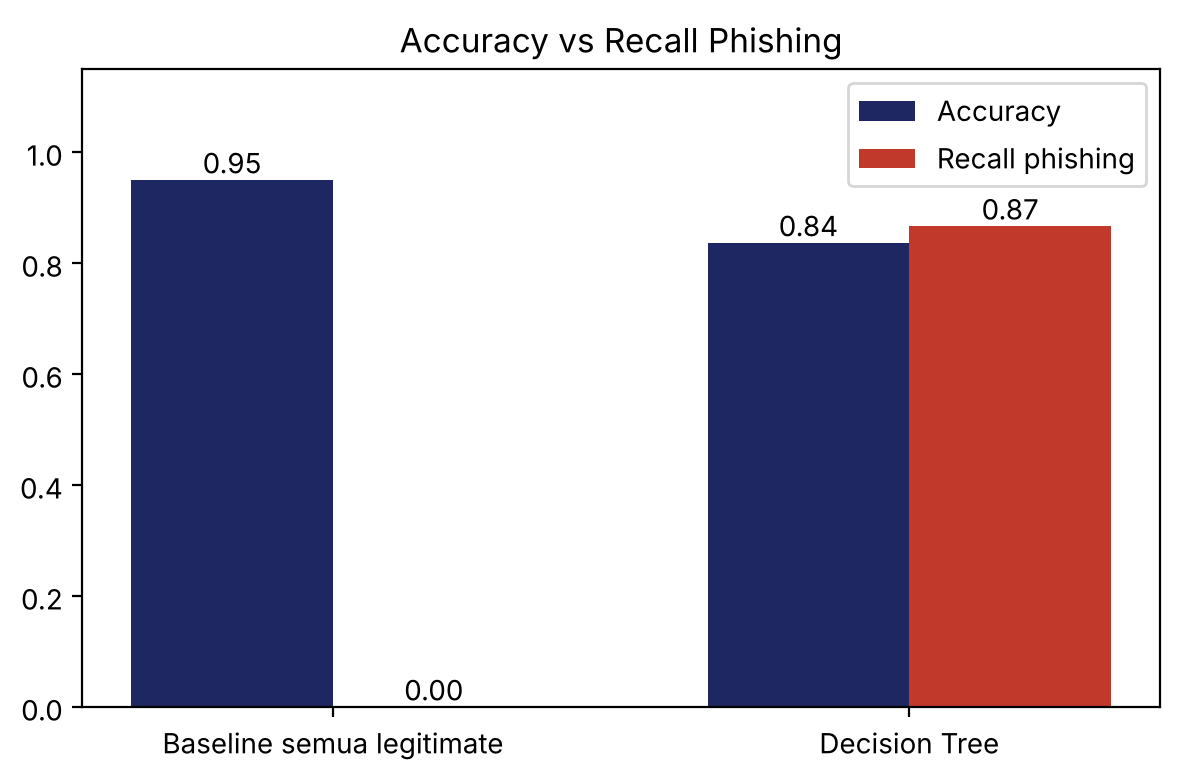

In [2]:
rows = []
for nama, p in [('Baseline semua legitimate', baseline), ('Decision Tree', y_pred)]:
    rows.append([nama, accuracy_score(y_test, p), precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p, zero_division=0), f1_score(y_test, p, zero_division=0)])
ringkas = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1'])
print(ringkas.round(3).to_string(index=False))
plt.figure(figsize=(6, 4))
xs = np.arange(2); w = 0.35
b1 = plt.bar(xs - w/2, ringkas['Accuracy'], w, label='Accuracy', color='#1E2761')
b2 = plt.bar(xs + w/2, ringkas['Recall'], w, label='Recall phishing', color='#C0392B')
plt.bar_label(b1, fmt='%.2f'); plt.bar_label(b2, fmt='%.2f')
plt.xticks(xs, ringkas['Model']); plt.ylim(0, 1.15); plt.legend()
plt.title('Accuracy vs Recall Phishing'); plt.tight_layout()
plt.savefig('fig_baseline.png', dpi=150); plt.show()
